# Exercise 1: Plotting functions

Consider the following function in one variable $x$, 
$$
f(x) = \sin(20 x) + 5 x^2
$$
which is the sum of the sine function and a quadratic function.

Perform the following tasks:

1.  Define a Python function that returns the function value $f(x)$ for some 
    argument $x$. The function should work with both scalar numbers and 
    NumPy arrays.

    *Hint:* The sine function is implemented in 
    [`np.sin()`](https://numpy.org/doc/stable/reference/generated/numpy.sin.html).

2.  Evaluate the function on a uniformly spaced grid of $x$-values
    on the interval $[-1, 1]$ using 51 grid points.

    Create a plot depicting the function on this interval. Set the
    $x$-ticks to the values $[-1, 0, 1]$ and add a legend.

3.  Locate the point $x_{min}$ where the function attains its minimum on the grid 
    you created and print the values $(x_{min}, f(x_{min}))$.

    *Hint:* You can use the NumPy function 
    [`np.argmin()`](https://numpy.org/doc/stable/reference/generated/numpy.argmin.html)
    for this.

4.  Augment the plot you created earlier with a horizontal and vertical
    line indicating where the minimum is located. Add a black dot at the point $(x_{min}, f(x_{min}))$.

    *Hint:* Horizontal and vertical lines can be added with 
    [`axhline()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html)
    and 
    [`axvline()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axvline.html).
    A single dot can be added in various ways, e.g., using 
    [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html).

5.  Repeat the exercise but now use $N=501$ grid points to evaluate the function.

## Solution

#### Part 1 — Defining the function

We implement the function using 
[`np.sin()`](https://numpy.org/doc/stable/reference/generated/numpy.sin.html)
so that it supports both scalar and array arguments.

In [1]:
import numpy as np


def fcn(x):
    """
    Compute f(x) = sin(20x) + 5x^2.
    """
    return np.sin(20 * x) + 5 * x**2.0

#### Part 2 — Evaluating and plotting the function

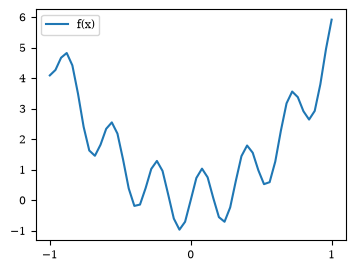

In [2]:
import matplotlib.pyplot as plt

N = 51
xvalues = np.linspace(-1, 1, N)
yvalues = fcn(xvalues)

plt.plot(xvalues, yvalues, label='f(x)')
plt.xticks((-1, 0, 1))
_ = plt.legend()

#### Part 3 — Locating the minimum

In [3]:
# Locate the index of the minimum value
imin = np.argmin(yvalues)

# Extract the x and y values at the minimum
xmin = xvalues[imin]
ymin = yvalues[imin]

print(f'Minimum at x = {xmin:.3f}, f(x) = {ymin:.3f}')

Minimum at x = -0.080, f(x) = -0.968


#### Part 4 — Visualizing the minimum

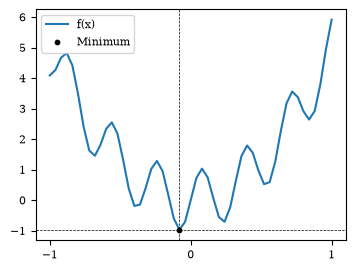

In [4]:
plt.plot(xvalues, yvalues, label='f(x)')

# Add dashed lines to indicate the minimum
plt.axvline(xmin, c='black', ls='--', lw=0.5)
plt.axhline(ymin, c='black', ls='--', lw=0.5)

# Add a black point to highlight the minimum
plt.scatter(xmin, ymin, c='black', label='Minimum', s=10, zorder=10)
plt.xticks((-1, 0, 1))
_ = plt.legend()

#### Part 5 — Increasing the grid size

We rerun the above code but increase the grid size to $N=501$. As you can see, this yields a much smoother plot, but also changes where the minimum is located since the function is evaluated on a much denser grid.

In [5]:
N = 501
xvalues = np.linspace(-1, 1, N)
yvalues = fcn(xvalues)

# Locate the index of the minimum value
imin = np.argmin(yvalues)

# Extract the x and y values at the minimum
xmin = xvalues[imin]
ymin = yvalues[imin]

print(f'Minimum at x = {xmin:.3f}, f(x) = {ymin:.3f}')

Minimum at x = -0.076, f(x) = -0.970


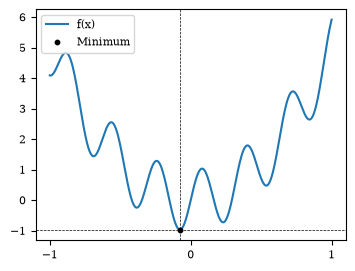

In [6]:
plt.plot(xvalues, yvalues, label='f(x)')

# Add dashed lines to indicate the minimum
plt.axvline(xmin, c='black', ls='--', lw=0.5)
plt.axhline(ymin, c='black', ls='--', lw=0.5)

# Add a black point to highlight the minimum
plt.scatter(xmin, ymin, c='black', label='Minimum', s=10, zorder=10)
plt.xticks((-1, 0, 1))
_ = plt.legend()

<span style="display: none;">SolutionEnd</span>

***
# Exercise 2: Visualizing US business cycles and recessions

In this exercise, you are asked to plot two main business cycle indicators, GDP growth and the unemployment rate, for the United States.

1.  Load the data from the CSV file `FRED/FRED_quarterly.csv` located in the repository's `data` folder.

    Familiarize yourself with the data by printing the columns present in the data set and the first 5 rows of data.

    *Hint:* Use 
    [`read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
    with `parse_dates=['DATE']` and `index_col='DATE'` to automatically parse strings stored in the `DATE` column as dates and set `DATE` as the index.

2.  Compute the quarterly GDP growth (i.e., the relative change of the column `GDP` vs. the previous quarter) in percent.

    *Hint:* This can be achieved using the 
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
    method.

3.  Create a figure with two subplots (arranged in 2 rows) which show the GDP growth and the unemployment rate.

    *Hint:* You can construct the graph either using Matplotlib's plotting function or using pandas's 
    [`DataFrame.plot()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html)
    method.

4.  You want to understand how the business cycle indicators behave around
    recession starts in the US. The National Bureau of Economic Research (NBER)
    is a research organization that dates US business cycles.

    The `peak` column records the month immediately before each recession starts.

    1.  Load the business cycle dates from `NBER_cycle_dates.csv` located in the
        `data/` folder.

        Drop all rows where the `peak` date is before 1948.

        *Hint:* Use `pd.read_csv(..., parse_dates=['peak', 'trough'])` to
        automatically parse strings in the `peak` and `trough` columns.

    2.  Loop through all remaining business cycle peak dates and add a vertical
        line to each of the two subplots for GDP growth and unemployment at each
        date. These lines mark the months immediately before recession starts.

    3.  Can you detect any patterns for GDP growth and the unemployment rate
        around recession starts?

## Solution

#### Part 1 — Loading the data

In [7]:
import pandas as pd

# Path to the data directory
DATA_PATH = '../../data/'

# Path to data file
file = f'{DATA_PATH}/FRED/FRED_quarterly.csv'

# Load the data from the CSV file, parse dates and set the index
df = pd.read_csv(file, index_col='DATE', parse_dates=['DATE'])

# Inspect columns present in the DataFrame
df.info(show_counts=True)

<class 'pandas.DataFrame'>
DatetimeIndex: 312 entries, 1948-01-01 to 2025-10-01
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Year      312 non-null    int64  
 1   Quarter   312 non-null    int64  
 2   GDP       312 non-null    float64
 3   CPI       312 non-null    float64
 4   UNRATE    312 non-null    float64
 5   FEDFUNDS  286 non-null    float64
 6   REALRATE  176 non-null    float64
 7   LFPART    312 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 21.9 KB


In [8]:
# Display the first few rows of the DataFrame
df.head(5)

,Year,Quarter,GDP,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART
DATE,,,,,,,,
1948-01-01,1948,1,2239.7,23.7,3.4,NaN,NaN,58.6
1948-04-01,1948,2,2276.7,23.8,3.9,NaN,NaN,59.0
1948-07-01,1948,3,2289.8,24.4,3.6,NaN,NaN,59.3
1948-10-01,1948,4,2292.4,24.3,3.7,NaN,NaN,58.7
1949-01-01,1949,1,2260.8,24.0,4.3,NaN,NaN,58.7


#### Part 2 — Computing GDP growth

We use 
[`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
to compute the relative change from the previous observation. We need to multiply by 100 to convert the growth rate to percent.

In [9]:
# Compute quarterly growth rate of GDP (in percent)
df['GDP_growth'] = df['GDP'].pct_change() * 100

#### Part 3 — Plotting GDP growth and unemployment

We can use two approaches to visualize the time series for GDP growth and the unemployment rate.
First, we use the pandas plotting functionality, in this case either 
[`DataFrame.plot()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html)
or 
[`DataFrame.plot.line()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.line.html),
where the latter simply makes explicit that we intend to plot lines.

Note that we need to pass the options `subplots=True` and `layout=(2,1)` to create two subplots arranged in two rows,
otherwise pandas places both time series into the same plot.

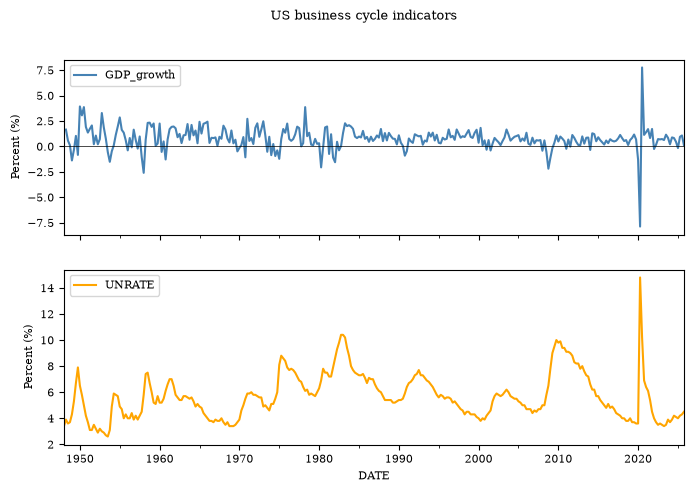

In [10]:
# Plot business cycle indicators using pandas's plotting capabilities
axes = df.plot.line(
    y=['GDP_growth', 'UNRATE'],  # Columns to plot
    figsize=(8, 5),  # Size of the figure
    subplots=True,  # Create subplot for each column
    layout=(2, 1),  # Layout of the subplots
    ylabel='Percent (%)',  # Y-axis label
    color=['steelblue', 'orange'],  # Colors for the lines
    title='US business cycle indicators',  # Title of the plot
)

# Highlight zero GDP growth
_ = axes[0, 0].axhline(0, c='black', ls='-', lw=0.5)

Alternatively, we can create the plot ourselves by directly using Matplotlib's functions.

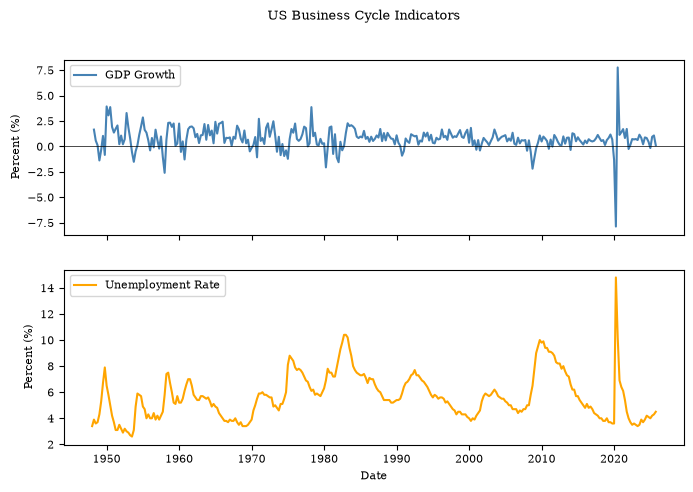

In [11]:
import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)

# Plot GDP growth and unemployment rate on separate axes
axes[0].plot(df.index, df['GDP_growth'], label='GDP Growth', c='steelblue')
axes[1].plot(df.index, df['UNRATE'], label='Unemployment Rate', c='orange')
axes[1].set_xlabel('Date')
fig.suptitle('US Business Cycle Indicators')

# Highlight zero GDP growth
axes[0].axhline(0, c='black', ls='-', lw=0.5)

# Set common options using a loop
for ax in axes:
    ax.set_ylabel('Percent (%)')
    ax.legend()

#### Part 4 — Adding recession indicators

We first load the business cycle data and keep observations from 1948 onward,
since our FRED data starts in 1948.

In [12]:
# Path to NBER business cycle dates file
file = f'{DATA_PATH}/NBER_cycle_dates.csv'

# Load NBER business cycle dates
df_dates = pd.read_csv(file, parse_dates=['peak', 'trough'])

In [13]:
# Keep only dates from 1948 onward
df_dates = df_dates[df_dates['peak'] >= '1948-01-01']

In [14]:
# Tabulate first five business cycle dates
df_dates.head()

,peak,trough
23,1948-11-01,1949-10-01
24,1953-07-01,1954-05-01
25,1957-08-01,1958-04-01
26,1960-04-01,1961-02-01
27,1969-12-01,1970-11-01


Next, we recreate the figure using Matplotlib, as in Part 3. Passing the
observation dates directly to `plot()` keeps the monthly peak dates at their
actual positions. The `axes` array returned by `plt.subplots(2, 1)` is
one-dimensional, so we loop directly over its two elements to add the recession
indicators.

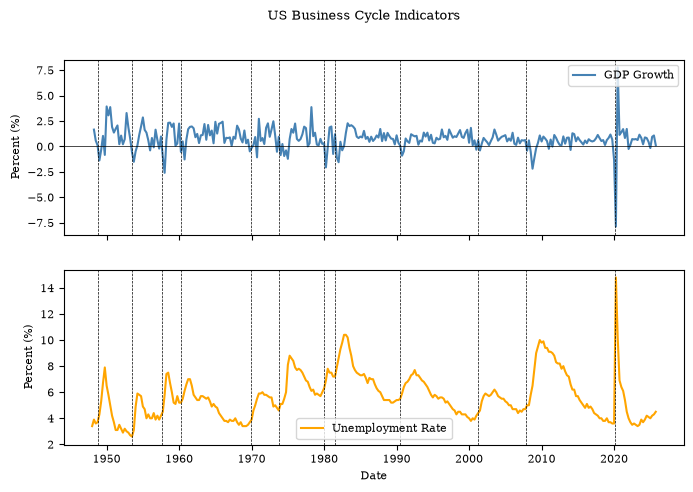

In [15]:
# Create a figure with two subplots
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)

# Plot the observations at their actual dates
axes[0].plot(df.index, df['GDP_growth'], label='GDP Growth', c='steelblue')
axes[1].plot(df.index, df['UNRATE'], label='Unemployment Rate', c='orange')

fig.suptitle('US Business Cycle Indicators')
axes[1].set_xlabel('Date')

for ax in axes:
    ax.set_ylabel('Percent (%)')
    ax.legend()

# Add the business cycle peak dates to both subplots
for date in df_dates['peak']:
    for ax in axes:
        ax.axvline(date, c='black', ls='--', lw=0.5)

# Highlight zero GDP growth
_ = axes[0].axhline(0, c='black', ls='-', lw=0.5)

Unemployment generally rises and GDP growth generally weakens around recession
starts. The timing varies across recessions, and GDP growth can remain positive
in some quarters during a recession.

<span style="display: none;">SolutionEnd</span>

***
# Exercise 3: Daily returns of US stock market indices

In this exercise, we examine how the three major US stock market indices performed in 2025.
Use the data in `indices.csv` from the folder `../../data/stockmarket` to solve the following tasks:

1.  Load the CSV data and restrict the sample to the calendar year 2025. 

    *Hint:* The data is tab-separated, so you need to specify `sep='\t'` when reading in the data.

    *Hint:* You should use 
    [`read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
    with `parse_dates=['Date']` to automatically parse strings stored in the `Date` column as dates.

2.  The data comes in a "long" format where each date-ticker combination is stored in 
    a separate row. For the following analysis, the data needs to be reshaped such that each 
    ticker symbol is in its own column ("wide" format).

    Use the 
    [`pivot()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html)
    method to reshape the `DataFrame` into the desired form. Consult the 
    [user guide](https://pandas.pydata.org/docs/user_guide/reshaping.html#pivot-and-pivot-table)
    to see a graphical illustration.

    Your pivoted `DataFrame` should look as follows:
    
    |    Ticker	 |   DJIA    | NASDAQ  |  SP500 |
    |------------|-----------|---------|--------|
    | Date		 |           |	       |        |
    | 2025-01-02 |	42392.3	 | 19280.8 | 5868.5 |
    | 2025-01-03 |  42732.1	 | 19621.7 | 5942.5 |
    
3.  Create a line plot which shows the time series for each of the three ticker symbols in a single graph,
    for example using 
    [`DataFrame.plot()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html).
4.  The graph you just created is not very satisfactory as the three
    indices are recorded on vastly different scales. Express each index
    relative to its initial value in 2025 (so that all three start with the value
    1.0) and recreate the previous graph with this normalized data.
5.  Another way to check whether the three indices are co-moving is to compute and plot their daily returns.
    For each index, compute the daily returns, i.e., the relative change vs. the previous closing price in percent (e.g., using 
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)), 
    and plot the three time series of daily returns in a single graph.
6.  The previous plots suggest that the three indices co-move a lot. 
    
    1.  In order to quantify the strength of 
        this co-movement, compute the pairwise correlations of daily returns using 
        [`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).

    2.  Create a figure with 3-by-3 subplots where each off-diagonal plot shows the 
        scatter plot for two of the indices.
    
        *Hint:* You can use the function 
        [`scatter_matrix()`](https://pandas.pydata.org/docs/reference/api/pandas.plotting.scatter_matrix.html)
        to accomplish this task. Alternatively, you can create a figure with 3-by-3 subplots using Matplotlib's 
        [`subplots()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html),
        iterate over all rows and columns and add a 
        [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)
        plot to each `axes` object.

    3.  Add the correlation coefficient for each stock market index pair 
        as text to the corresponding subplot in the figure you created
        (this can be done using 
        [`text()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.text.html)).

## Solution

#### Part 1 — Loading the data

In [16]:
# Use files in the local data/stockmarket directory
DATA_PATH = '../../data/stockmarket'

# Uncomment this to load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH2-H26/main/data/stockmarket'

In [17]:
import pandas as pd

# path to CSV file
path = f'{DATA_PATH}/indices.csv'

# Parse data using tab character as separator
df = pd.read_csv(path, sep='\t', parse_dates=['Date'])

# Restrict dates to year 2025
df = df.query('Date >= 2025 & Date < 2026')

# Restore default index after dropping other years
df = df.reset_index(drop=True)

In [18]:
# Print first 3 observations
df.head(3)

,Date,Ticker,Price
0,2025-01-02,DJIA,42392.3
1,2025-01-02,SP500,5868.5
2,2025-01-02,NASDAQ,19280.8


In [19]:
# Print last 3 observations
df.tail(3)

,Date,Ticker,Price
744,2025-12-30,DJIA,48367.1
745,2025-12-30,SP500,6896.2
746,2025-12-30,NASDAQ,23419.1


#### Part 2 — Reshaping the data with `pivot()`

The values in column `Ticker` should provide the new column names, with values given by the column `Price`. The `Date` column is the (unique) index of the pivoted `DataFrame`.

In [20]:
# Reshape DataFrame, move ticker symbols to individual columns
df = df.pivot(index='Date', columns='Ticker', values='Price')

df.head(5)

Ticker,DJIA,NASDAQ,SP500
Date,,,
2025-01-02,42392.3,19280.8,5868.5
2025-01-03,42732.1,19621.7,5942.5
2025-01-06,42706.6,19865.0,5975.4
2025-01-07,42528.4,19489.7,5909.0
2025-01-08,42635.2,19478.9,5918.2


#### Part 3 — Plotting the raw data

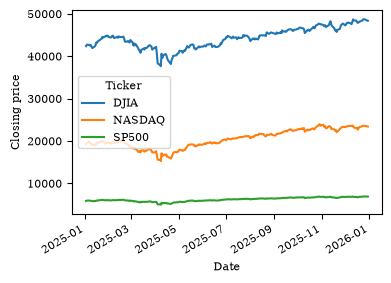

In [21]:
# Plot all three indices, setting a label for the y-axis.
_ = df.plot.line(ylabel='Closing price')

#### Part 4 — Plotting the normalized data

One way to normalize each column by its first value is to select the first row and divide the data by this row:

In [22]:
# Use .iloc[0] to select the first row, divide data by values in first row.
df_norm = df / df.iloc[0]

You can use 
[`head()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)
to verify that the first normalized element of each column is now 1.

In [23]:
df_norm.head(3)

Ticker,DJIA,NASDAQ,SP500
Date,,,
2025-01-02,1.000000,1.000000,1.000000
2025-01-03,1.008016,1.017681,1.012610
2025-01-06,1.007414,1.030300,1.018216


Finally, we plot the normalized indices just like in the previous sub-question. It is now much easier to see that these indices moved very similarly in 2025.

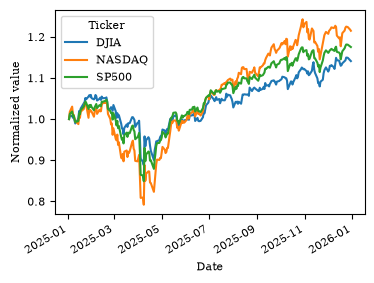

In [24]:
_ = df_norm.plot.line(ylabel='Normalized value')

#### Part 5 — Plotting the daily returns

We use the 
[`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
method to compute the relative difference between two consecutive closing prices.

In [25]:
# Relative difference from previous closing price in percent
df_returns = df.pct_change() * 100.0

Because we cannot compute a difference for the very first observation, these values are set to `NaN`.

In [26]:
df_returns.head(3)

Ticker,DJIA,NASDAQ,SP500
Date,,,
2025-01-02,NaN,NaN,NaN
2025-01-03,0.801561,1.768080,1.260970
2025-01-06,-0.059674,1.239954,0.553639


We plot the daily returns using the pandas plotting functions as before. The figure confirms that the daily returns for all three indices tend to be very similar.

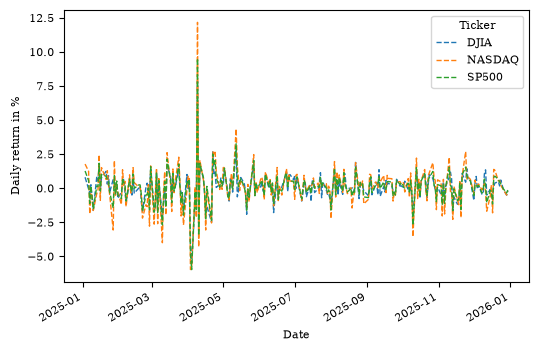

In [27]:
# use dashed lines since daily returns are overlapping
_ = df_returns.plot.line(ylabel='Daily return in %', lw=1.0, ls='--', figsize=(6, 4))

#### Part 6 — Scatter plots of daily returns

To compute the pairwise correlation between all columns, we call 
[`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).
The results show that all three daily returns are highly correlated, which is what we would have expected from looking at the time series of daily returns we plotted earlier.

Note that in all these operations, the `NaN` values in the first row are automatically excluded.

In [28]:
df_corr = df_returns.corr()
df_corr

Ticker,DJIA,NASDAQ,SP500
Ticker,,,
DJIA,1.000000,0.837790,0.925805
NASDAQ,0.837790,1.000000,0.972275
SP500,0.925805,0.972275,1.000000


Recall that the correlation coefficient takes values in the interval $[-1, 1]$.
A positive value means that two variables tend to move in the same direction,
whereas the opposite is true for a negative value. An absolute value close to 1
indicates a strong linear relationship, whereas values around zero indicate
little linear association. A correlation near zero does not rule out a nonlinear
relationship.

We can visualize the pairwise relationships between daily returns using
[`scatter_matrix()`](https://pandas.pydata.org/docs/reference/api/pandas.plotting.scatter_matrix.html)
from the module `pandas.plotting`, which takes a `DataFrame` as its argument and creates pairwise scatter plots for all columns. The function plots either a histogram or a kernel density plot along the main diagonal, since creating a scatter plot of one and the same variable against itself just yields a diagonal line!

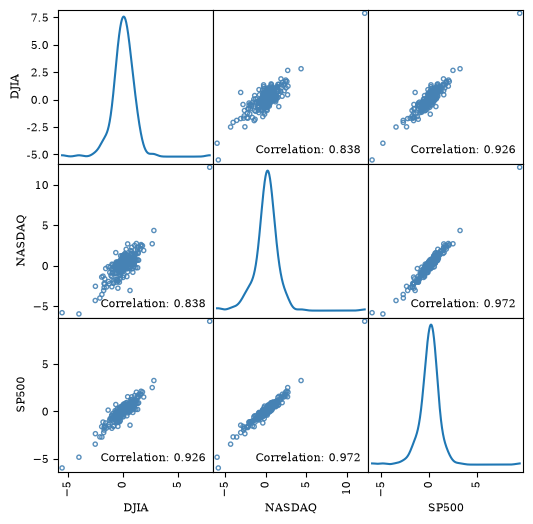

In [29]:
from pandas.plotting import scatter_matrix

# Create figure with 3x3 scatter plots. Main diagonal shows kernel density
# for each index.
axes = scatter_matrix(
    df_returns,
    figsize=(6, 6),
    alpha=0.9,
    c='none',
    edgecolors='steelblue',
    diagonal='kde',
)

# Iterate over subplots, add correlation text to each off-diagonal panel
for i in range(axes.shape[0]):
    for j in range(axes.shape[1]):
        # Skip diagonal panels, correlation is 1.0 by construction
        if i == j:
            continue
        # Reference to current Axes object (subplot)
        ax = axes[i, j]
        c = df_corr.iloc[i, j]
        ax.text(
            0.95,
            0.05,
            f'Correlation: {c:.3f}',
            transform=ax.transAxes,
            va='bottom',
            ha='right',
        )

Alternatively, we can create the 3-by-3 scatter plots manually. We first ask Matplotlib to create a figure with 3-by-3 panels and then iterate over rows and columns, using 
[`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)
to add the bivariate scatter plot to each panel.

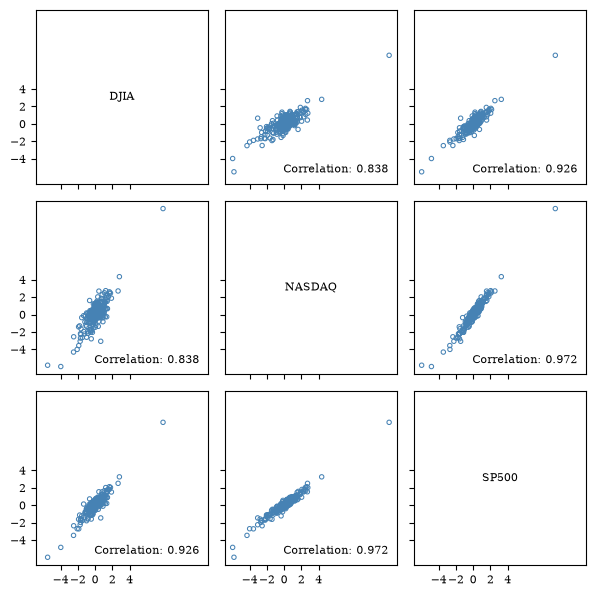

In [30]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 3, figsize=(6, 6), sharex=True, sharey=True)

# Index names used as labels along the diagonal
labels = df_returns.columns.to_list()

# Iterate over rows and columns
for i in range(axes.shape[0]):
    for j in range(axes.shape[1]):
        # Reference to current Axes object (subplot)
        ax = axes[i, j]

        # For diagonal panels, print the index name instead of the
        # (exactly diagonal) scatter plot.
        if i == j:
            ax.text(
                0.5, 0.5, labels[i], transform=ax.transAxes, va='center', ha='center'
            )
            continue

        # Get x- and y-values for this panel
        xvalues = df_returns.iloc[:, j]
        yvalues = df_returns.iloc[:, i]

        ax.scatter(xvalues, yvalues, s=10, alpha=1.0, lw=0.75, c='none', ec='steelblue')

        # Set uniform x- and y-ticks for all axes
        ticks = np.linspace(-4, 4, 5)
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)

        # Add correlation to any off-diagonal graphs
        if i != j:
            c = df_corr.iloc[i, j]
            ax.text(
                0.95,
                0.05,
                f'Correlation: {c:.3f}',
                transform=ax.transAxes,
                va='bottom',
                ha='right',
            )

# Reduce spacing between subplots
fig.tight_layout()

<span style="display: none;">SolutionEnd</span>

***
# Exercise 4: Population and electric cars in Norway

How do Norwegian municipalities differ in population size, population density,
and the use of electric cars? Use the data in
`../../data/ssb/municipalities.csv` to explore these questions.

The file contains one row per municipality. The variables needed here are:

- `municipality`: Municipality name.
- `population`: Number of residents.
- `land_area`: Land area in square kilometers, excluding freshwater.
- `cars`: Number of registered passenger cars, including electric cars.
- `electric_cars`: Number of electric passenger cars, excluding hybrids.

The data come from Statistics Norway (SSB); see the
[data description](../../data/ssb/README.md) for details.

1.  Load the variables listed above into a `DataFrame`. Display the first
    five rows and count the municipalities. Are any of the population, land
    area, or car counts missing?

    *Hint:* Use the `usecols` argument of
    [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
    to select columns, and
    [`DataFrame.info()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)
    with `show_counts=True` to inspect the number of nonmissing observations.

2.  Create a new column `pop_density` containing population divided by land area.
    This measures residents per square kilometer.

    Create a figure with two histograms arranged in one row: population size
    and population density. Use 30 bins in each histogram.
    Express population in thousands and label both axes.

    *Hint:* Use `plt.subplots(1, 2)` and the
    [`hist()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)
    method of each `Axes` object. The height of each bar should show the
    number of municipalities in that bin.

3.  Compute the percentage of passenger cars that are electric in each
    municipality as `100 * electric_cars / cars`, and store it in a new
    column `ev_share`.

    Create a second figure with two histograms arranged in one row: the
    number of electric cars (in thousands) and the EV share (in percent).
    Again, use 30 bins and label both axes.

    How do these distributions differ? Why might the EV share be more useful
    than the number of electric cars when comparing municipalities?

4.  Create a scatter plot with population density on the horizontal axis and
    the EV share (in percent) on the vertical axis. Use one equally sized
    point per municipality and some transparency to make overlapping points
    easier to see.

    Describe the relationship between population density and the EV share.

5.  **[Advanced]** Recreate the scatter plot with a logarithmic
    horizontal axis. Keep the EV share on its original percentage scale.

    *Hint:* Use
    [`set_xscale()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xscale.html)
    with `'log'`. Equal distances on this axis represent equal ratios:
    moving from 1 to 10 residents per square kilometer takes the same space
    as moving from 10 to 100.

    Why is this plot easier to read?

## Solution

#### Part 1 — Loading the data

In [31]:
import pandas as pd

DATA_PATH = '../../data'
filepath = f'{DATA_PATH}/ssb/municipalities.csv'

columns = ['municipality', 'population', 'land_area', 'cars', 'electric_cars']
df_muni = pd.read_csv(filepath, usecols=columns)
df_muni.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   municipality   357 non-null    str  
 1   population     357 non-null    int64
 2   land_area      357 non-null    int64
 3   cars           357 non-null    int64
 4   electric_cars  357 non-null    int64
dtypes: int64(4), str(1)
memory usage: 14.1 KB


In [32]:
df_muni.head()

,municipality,population,land_area,cars,electric_cars
0,Oslo,724290,426,246809,120469
1,Bergen,293709,445,122239,60695
2,Trondheim - Tråante,216518,496,92529,37742
3,Stavanger,150123,256,69615,27663
4,Bærum,132358,189,78279,38369


In [33]:
print(f'Number of municipalities: {len(df_muni)}')

Number of municipalities: 357


There are 357 municipalities, and all variables used in this exercise have
357 nonmissing observations.

#### Part 2 — Population size and density

We calculate density from population and land area. Both are positive for
every municipality in this data set.

In [34]:
df_muni['pop_density'] = df_muni['population'] / df_muni['land_area']

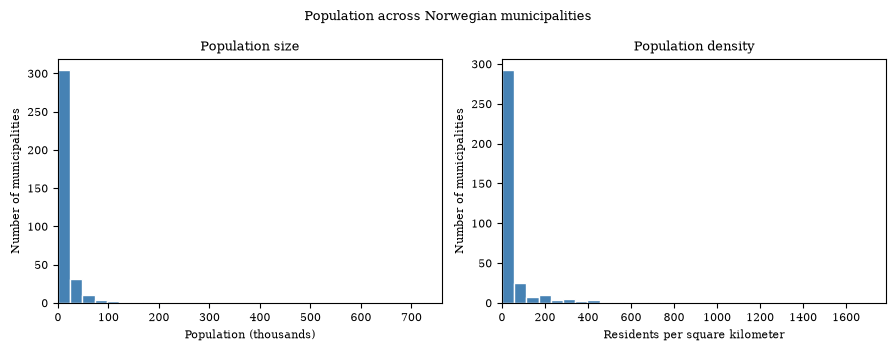

In [35]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))

ax1.hist(df_muni['population'] / 1000, bins=30, color='steelblue', ec='white')
ax1.set_title('Population size')
ax1.set_xlabel('Population (thousands)')

ax2.hist(df_muni['pop_density'], bins=30, color='steelblue', ec='white')
ax2.set_title('Population density')
ax2.set_xlabel('Residents per square kilometer')

for ax in (ax1, ax2):
    ax.set_ylabel('Number of municipalities')
    ax.set_xlim(left=0)

fig.suptitle('Population across Norwegian municipalities')
fig.tight_layout()

Both distributions have long right tails: most municipalities have small
populations and low densities, while a few have much larger values. The large
values stretch the horizontal axes, placing many municipalities in the first
few bins. Keeping all municipalities makes this uneven distribution visible,
but hides differences among the smaller municipalities.

Each municipality contributes one observation, regardless of its population.
These histograms therefore describe the distribution of municipalities,
rather than the distribution of residents across municipalities.

#### Part 3 — Electric cars and shares

The denominator includes all passenger cars, including electric cars.
Multiplying the ratio by 100 expresses the EV share in percent.

In [36]:
df_muni['ev_share'] = 100 * df_muni['electric_cars'] / df_muni['cars']

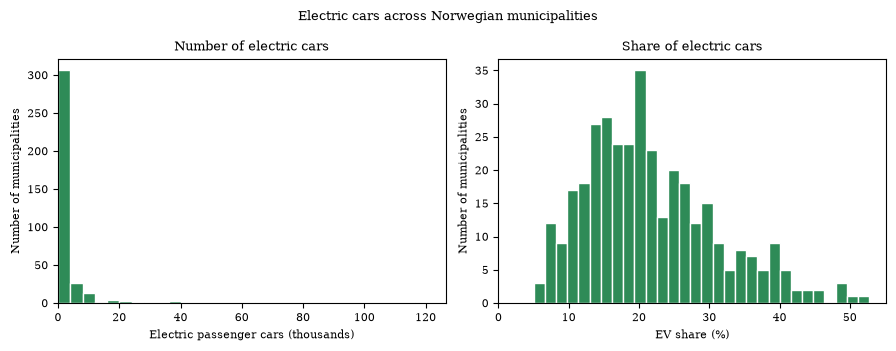

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))

ax1.hist(df_muni['electric_cars'] / 1000, bins=30, color='seagreen', ec='white')
ax1.set_title('Number of electric cars')
ax1.set_xlabel('Electric passenger cars (thousands)')

ax2.hist(df_muni['ev_share'], bins=30, color='seagreen', ec='white')
ax2.set_title('Share of electric cars')
ax2.set_xlabel('EV share (%)')

for ax in (ax1, ax2):
    ax.set_ylabel('Number of municipalities')
    ax.set_xlim(left=0)

fig.suptitle('Electric cars across Norwegian municipalities')
fig.tight_layout()

The number of electric cars has a long right tail, much like population.
The EV share is more evenly spread out, ranging from about 5% to 53%;
most municipalities have shares between roughly 10% and 30%.

A municipality can have many electric cars simply because it has many cars
overall. Dividing by the total number of cars makes municipalities of different
sizes easier to compare. The share describes the registered passenger car
fleet, not the share of new car sales that are electric.

#### Part 4 — Density and EV shares

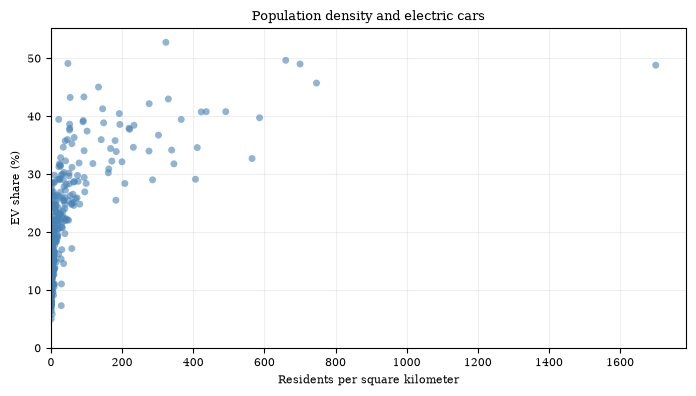

In [38]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    df_muni['pop_density'],
    df_muni['ev_share'],
    s=25,
    alpha=0.6,
    c='steelblue',
    ec='none',
)
ax.set_xlabel('Residents per square kilometer')
ax.set_ylabel('EV share (%)')
ax.set_title('Population density and electric cars')
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()

Municipalities with higher population density tend to have higher EV shares.
There is also substantial variation in EV shares among municipalities with
similar densities. Most points are crowded near the left edge because a few
municipalities have much higher densities than the rest.

This is an association, not evidence that density causes EV adoption. The plot
does not account for other differences between municipalities, such as income
or access to charging.

#### Part 5 — A logarithmic density axis [Advanced]

A logarithmic scale changes the spacing on the horizontal axis. The
densities remain in residents per square kilometer, and the EV shares remain
in percent. All calculated densities are positive, so every municipality can
be shown on the logarithmic axis.

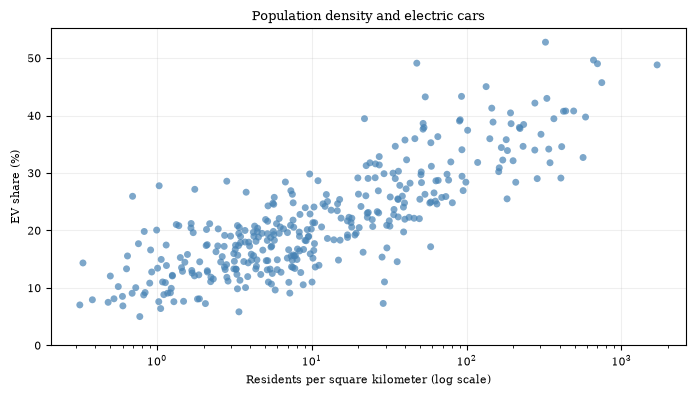

In [39]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    df_muni['pop_density'],
    df_muni['ev_share'],
    s=25,
    alpha=0.7,
    c='steelblue',
    ec='none',
)
ax.set_xscale('log')
ax.set_xlabel('Residents per square kilometer (log scale)')
ax.set_ylabel('EV share (%)')
ax.set_title('Population density and electric cars')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()

The logarithmic axis spreads out the low densities and compresses the high
densities. It makes the positive association easier to see while retaining all
357 municipalities. The observations and their EV shares are unchanged.
<span style="display: none;">SolutionEnd</span>

***
# Exercise 5: Cruise ship arrivals in Bergen

How do cruise ship arrivals in Bergen vary over time and across seasons?
Use `kystverket/bergen_monthly_calls.csv` in the repository's `data/` folder
to explore these questions.

The file contains monthly arrival counts by vessel type. The variables needed
here are:

- `month`: Arrival month, stored as `YYYY-MM`.
- `vessel_type`: Detailed vessel type.
- `calls`: Monthly aggregate number of reported arrivals, including repeat visits
  by the same ship.

The cruise category also includes some coastal service vessels. The data come
from Kystverket; see the
[data description](../../data/kystverket/README.md) for details.

1.  Load the CSV file into a `DataFrame`. Display the first five rows and
    determine the sample period.

    *Hint:* Use
    [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
    with `parse_dates=['month']` and `date_format='%Y-%m'` to parse the dates.
    Each month will be represented by its first day.

2.  Select observations with `vessel_type` equal to `'Passenger/Cruise'`.
    Restrict the sample to the complete calendar years **2013–2025**.
    Set `month` as the index and sort chronologically. Use this selection
    for all remaining parts.

    *Hint:* After parsing `month` as a datetime column, you can compare it
    directly with date strings. For example,
    `df_calls['month'] >= '2013-01-01'` selects observations on or after
    January 1, 2013. Combine two comparisons to select the required date range.

3.  Create a line plot of monthly cruise ship arrivals over the selected sample.
    Label both axes and add a title. Find the month with the most arrivals,
    print the month and its arrival count, and indicate the month with a vertical
    line in the plot.
    Describe the seasonal pattern and the changes visible around 2020–2021.

    *Hint:* The
    [`idxmax()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.idxmax.html)
    method returns the index label of the first maximum.

4.  Compute the average number of arrivals for each calendar month using a loop.
    For each month from January through December, select the corresponding
    observations, compute the mean of `calls`, and append it to a list.

    Create a bar chart of the 12 averages, with month names on the horizontal
    axis. Which months have the most arrivals on average?

    *Hint:* Loop over `range(1, 13)`. The `df_cruise.index.month` attribute
    gives the calendar month (1 for January through 12 for December) of each
    observation.

## Solution

#### Part 1 — Loading the data

We parse the month column as datetimes. The first day represents each month;
it does not imply that all arrivals took place on that day.

In [40]:
import pandas as pd

DATA_PATH = '../../data/kystverket'
filepath = f'{DATA_PATH}/bergen_monthly_calls.csv'

df_calls = pd.read_csv(filepath, parse_dates=['month'], date_format='%Y-%m')
df_calls.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 14850 entries, 0 to 14849
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   month            14850 non-null  datetime64[us]
 1   vessel_type      14850 non-null  str           
 2   vessel_category  14850 non-null  str           
 3   calls            14850 non-null  int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 464.2 KB


In [41]:
df_calls.head()

,month,vessel_type,vessel_category,calls
0,2013-01-01,"Accommodation Platform, semi submersible",Offshore and special-purpose vessels,0
1,2013-01-01,Aggregates Carrier,Cargo ships,2
2,2013-01-01,Anchor Handling Tug Supply,Offshore and special-purpose vessels,27
3,2013-01-01,Anchor Handling Vessel,Offshore and special-purpose vessels,0
4,2013-01-01,Asphalt/Bitumen Tanker,Tankers,0


In [42]:
first_month = df_calls['month'].min()
last_month = df_calls['month'].max()
print(f'Sample period: {first_month:%Y-%m} to {last_month:%Y-%m}')

Sample period: 2013-01 to 2026-09


#### Part 2 — Selecting cruise ships

We combine the vessel type and date conditions using `&`. The upper date bound
excludes 2026, so every selected year contains all 12 months.

In [43]:
df_cruise = df_calls[
    (df_calls['vessel_type'] == 'Passenger/Cruise')
    & (df_calls['month'] >= '2013-01-01')
    & (df_calls['month'] < '2026-01-01')
]

df_cruise = df_cruise.set_index('month').sort_index()
df_cruise.head()

,vessel_type,vessel_category,calls
month,,,
2013-01-01,Passenger/Cruise,Passenger ships,0
2013-02-01,Passenger/Cruise,Passenger ships,4
2013-03-01,Passenger/Cruise,Passenger ships,4
2013-04-01,Passenger/Cruise,Passenger ships,5
2013-05-01,Passenger/Cruise,Passenger ships,48


In [44]:
print(f'Number of months: {len(df_cruise)}')

Number of months: 156


#### Part 3 — Plotting monthly arrivals

After selecting the vessel type, there is one observation per month. We use
`idxmax()` to find the date of the maximum and select its arrival count with
`loc`. We then plot the monthly counts and indicate the busiest month with a
vertical line.

In [45]:
peak_month = df_cruise['calls'].idxmax()
peak_calls = df_cruise.loc[peak_month, 'calls']

print(f'Busiest month: {peak_month:%B %Y}, with {peak_calls} arrivals')

Busiest month: June 2017, with 90 arrivals


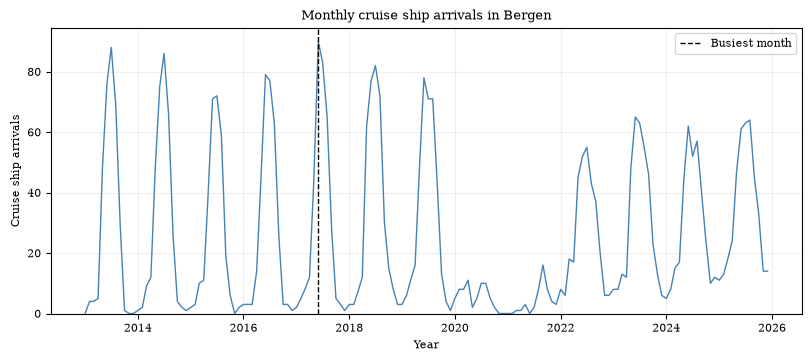

In [46]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')

ax.plot(df_cruise.index, df_cruise['calls'], c='steelblue', lw=1)
ax.axvline(peak_month, c='black', ls='--', lw=1, label='Busiest month')
ax.set_xlabel('Year')
ax.set_ylabel('Cruise ship arrivals')
ax.set_title('Monthly cruise ship arrivals in Bergen')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
_ = ax.legend()

Arrivals are strongly seasonal, with peaks in summer and much lower counts in
winter. There is a pronounced drop in 2020 and 2021, during the COVID-19
pandemic.

#### Part 4 — Averaging by calendar month

For each calendar month, we select the 13 observations from 2013 through 2025.
The loop appends their mean to a list, preserving the order from January
through December.

In [47]:
months = range(1, 13)
average_calls = []

for month in months:
    df_month = df_cruise[df_cruise.index.month == month]
    average_calls.append(df_month['calls'].mean())

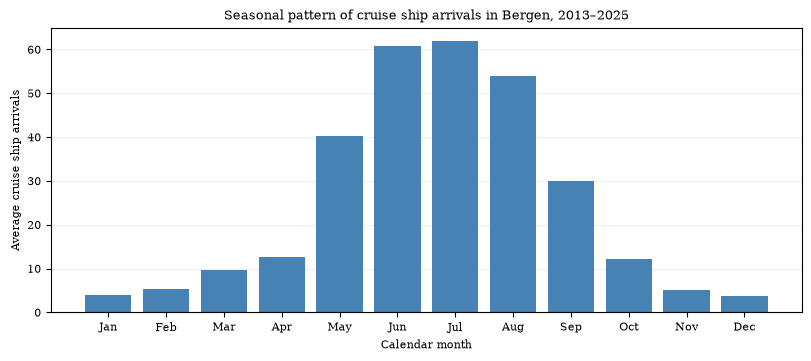

In [48]:
month_names = [
    'Jan',
    'Feb',
    'Mar',
    'Apr',
    'May',
    'Jun',
    'Jul',
    'Aug',
    'Sep',
    'Oct',
    'Nov',
    'Dec',
]

fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')

ax.bar(months, average_calls, color='steelblue')
ax.set_xticks(months, labels=month_names)
ax.set_xlabel('Calendar month')
ax.set_ylabel('Average cruise ship arrivals')
ax.set_title('Seasonal pattern of cruise ship arrivals in Bergen, 2013–2025')
ax.grid(axis='y', alpha=0.2)
# Draw the grid behind the bars so it does not cross over them.
ax.set_axisbelow(True)

June and July have the highest average arrival counts, followed by August.
The winter months have the lowest averages. Averaging the same calendar month
across years makes the seasonal pattern easier to see.

<span style="display: none;">SolutionEnd</span>